# W-01 — Methods and results from the current data

**Inputs.** Seven frozen task summaries and three attributed figures, held in the central input directory.
**Motivation.** The new microscopy data add quantitative observations to the reference-sequence,
plate-reader and stored PAH analyses.
**Goal.** Reproduce a short local methods/results draft with traceable source statements and figures.
**Prediction.** A consistent draft can connect the findings while preserving what each measurement means.

In [1]:
from pathlib import Path
import hashlib, json, platform, shutil
import pandas as pd
from IPython.display import Markdown, Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/input').is_dir() and (p / 'tasks').is_dir())
INPUT = ROOT / 'data/input'
OUT = ROOT / 'data/output/W-01'
OUT.mkdir(parents=True, exist_ok=True)
TASKS = ['C-06', 'D-01', 'F-01', 'C-EX', 'P-01', 'P-02', 'V-01']
FILES = {task: INPUT / f'W01_{task.replace("-", "")}_summary.json' for task in TASKS}
FIGURE_FILE = INPUT / 'W01_figure_sources.json'
LABELS = {'C-06': 'Reference coding sequence', 'D-01': 'Native plate-reader signals',
          'F-01': 'Native microscopy and recording behavior', 'C-EX': 'Evidence review',
          'P-01': 'Stored PAH calculations', 'P-02': 'Conditional PAH models',
          'V-01': 'Conceptual calcium reporter'}

## Materials and methods

Read the frozen JSON summaries and copy their result sentences, methods, interpretations and
figure captions with their task identifiers. Copy the selected PNG and SVG files unchanged.
Record hashes of every input and verify the copied figure bytes. The output is an offline draft.

**Scope and working assumptions.** Each source retains its own Methods scope: C-06 concerns a
reference sequence, F-01 uses recorded pixels and acquisition-relative clocks where recovered,
and C-EX reviews evidence rather than identifying an expression defect. Nominal sample/dose labels
and unresolved culture identities remain as documented. PAH calculations and assumed model
parameters are separate from the cadmium experiment. This notebook does not repeat upstream
scientific calculations or establish publication approval.

In [2]:
summaries = {task: json.loads(path.read_text(encoding='utf-8')) for task, path in FILES.items()}
figures = json.loads(FIGURE_FILE.read_text(encoding='utf-8'))
source_rows, findings, figure_rows = [], [], []
for task, path in FILES.items():
    source_rows.append({'task': task, 'input_file': path.name,
                        'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
    for result in summaries[task]['results']:
        findings.append({'task': task, 'result': result})
for item in figures:
    for suffix in ['png', 'svg']:
        source = INPUT / (item['input_stem'] + '.' + suffix)
        target = OUT / (item['output_stem'] + '.' + suffix)
        shutil.copyfile(source, target)
        sha = hashlib.sha256(source.read_bytes()).hexdigest()
        assert hashlib.sha256(target.read_bytes()).hexdigest() == sha
        figure_rows.append({'task': item['task'], 'input_file': source.name,
                            'output_file': target.name, 'sha256': sha,
                            'underlying_data': item['underlying_data'], 'caption': item['caption']})
pd.DataFrame(source_rows).to_csv(OUT / 'source_index.csv', index=False)
pd.DataFrame(findings).to_csv(OUT / 'result_index.csv', index=False)
pd.DataFrame(figure_rows).to_csv(OUT / 'figure_index.csv', index=False)
lines = ['# Current-data methods and results', '', '## Materials and methods', '',
         'Seven frozen task summaries are the sources. The analyses use the supplied reference, '
         'native instrument records, recorded microscopy, stored PAH calculations and declared '
         'model assumptions. All source statements retain their original analytical scope.', '']
for task in TASKS:
    lines += [f'**{task} — {LABELS[task]}.** ' + ' '.join(summaries[task]['methods'][:2]), '']
lines += ['## Results', '']
for task in TASKS:
    lines += [f'**{task} — {LABELS[task]}.** ' + ' '.join(summaries[task]['results'][:2]), '',
              summaries[task]['conclusion'], '']
lines += ['## Figures', '']
for i, item in enumerate(figures, 1):
    lines += [f'![Figure {i}]({item["output_stem"]}.png)', '',
              f'Figure {i}. From {item["task"]}: {item["caption"]}', '',
              'Underlying data: ' + item['underlying_data'], '']
references = list(dict.fromkeys(str(r) for task in TASKS for r in summaries[task]['references']))
lines += ['## References and reproducibility', '',
          'source_index.csv and figure_index.csv retain source hashes and attribution. '
          'result_index.csv contains every upstream result sentence. The original calculations '
          'and all code are in the standalone task notebooks.', ''] + ['- ' + r for r in references]
draft = '\n'.join(lines)
(OUT / 'wiki_results.md').write_text(draft, encoding='utf-8')
report_table = pd.DataFrame([{'Task': task, 'Evidence': LABELS[task], 'Input data': FILES[task].name,
    'Finished without more wet-lab data?': 'Yes: offline synthesis'} for task in TASKS])
report_table.to_csv(OUT / 'task_scope.csv', index=False)
conclusion = (f'The draft integrates {len(TASKS)} source analyses and {len(figures)} unchanged '
              'figures with numerical statements, methods and source indexes. Native imaging '
              'findings and the reference-sequence analysis now appear alongside the evidence '
              'review and the separate PAH computations.')
summary = {'title': 'W-01: expanded current-data methods and results',
    'question': 'What do the current analyses support in a concise local Wiki draft?',
    'materials': ['Seven frozen source summaries and three attributed PNG/SVG figure pairs.'],
    'methods': ['Retain source statements and task identifiers; generate the local draft and indexes inline.',
                'Copy attributed figures unchanged and verify input/output hashes.'],
    'scope_and_assumptions': 'The upstream Methods scopes and nominal-condition assumptions are retained. '
        'This is an offline synthesis, without new experiments, upstream recalculation or publication approval.',
    'results': [f'Integrated {len(TASKS)} source summaries and {len(figures)} attributed figures.',
                'Expanded microscopy: ' + summaries['F-01']['conclusion'],
                'Expression evidence: ' + summaries['C-EX']['conclusion'],
                'Reference sequence: ' + summaries['C-06']['results'][0]],
    'conclusion': conclusion, 'table': {'columns': report_table.columns.tolist(),
                                     'rows': report_table.values.tolist()},
    'figures': [{'file': r['output_file'], 'caption': 'From '+r['task']+': '+r['caption']}
                for r in figure_rows if r['output_file'].endswith('.png')], 'references': references}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
provenance = {'python': platform.python_version(), 'pandas': pd.__version__, 'sources': source_rows,
    'figures': figure_rows, 'figure_manifest_sha256': hashlib.sha256(FIGURE_FILE.read_bytes()).hexdigest()}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')

4328

## Results

,Task,Evidence,Input data,Finished without more wet-lab data?
0,C-06,Reference coding sequence,W01_C06_summary.json,Yes: offline synthesis
1,D-01,Native plate-reader signals,W01_D01_summary.json,Yes: offline synthesis
2,F-01,Native microscopy and recording behavior,W01_F01_summary.json,Yes: offline synthesis
3,C-EX,Evidence review,W01_CEX_summary.json,Yes: offline synthesis
4,P-01,Stored PAH calculations,W01_P01_summary.json,Yes: offline synthesis
5,P-02,Conditional PAH models,W01_P02_summary.json,Yes: offline synthesis
6,V-01,Conceptual calcium reporter,W01_V01_summary.json,Yes: offline synthesis


# Current-data methods and results

## Materials and methods

Seven frozen task summaries are the sources. The analyses use the supplied reference, native instrument records, recorded microscopy, stored PAH calculations and declared model assumptions. All source statements retain their original analytical scope.

**C-06 — Reference coding sequence.** Format only LOCUS metadata spacing in memory; verify ORIGIN bases and raw-file hashes are unchanged. Extract the labelled CDS and translate with standard nuclear code 1; record adjacent stop separately. Derive weights from integer counts within full synonymous families; replace true zeros by 0.5; exclude Met, Trp and stops from CAI. Sensitivity: zero = 1.

**D-01 — Native plate-reader signals.** Decompress JSON and map values with the stored physical row/column indices. Summarize each GUID/gain separately. Plot independent native-value colour scales. No gain conversion, condition assignment, blank or OD correction.

**F-01 — Native microscopy and recording behavior.** Stream native frames; distinguish T,C,P,Z axes; cross-check ND2 timestamps against per-frame metadata. Use acquired event Z coordinates and cross-check optical stacks against Z index and planned positions. Whole-field native means are primary. Estimate spatial background outside BF-derived regions; keep raw means and a 10th-percentile background sensitivity.

**C-EX — Evidence review.** Preserve source result sentences verbatim; classify evidence type without scores or statistical tests. Compare the measured scope with the measurement each causal explanation requires.

**P-01 — Stored PAH calculations.** Recalculate ranks within tool and target; do not pool scoring scales. Summarize strict distance <0.5 nm over each finite trace and extract reported rescoring means/SD.

**P-02 — Conditional PAH models.** Analytical single-site occupancy and fixed-ligand approach to equilibrium. Source reporter ODE integrated by DOP853 (rtol 1e-8; atol 1e-10) on a one-minute output grid.

**V-01 — Conceptual calcium reporter.** Draw cpGFP, CaM and M13 as labelled conceptual domains. Show calcium-associated CaM-M13 interaction and emission under excitation. Export original SVG/PNG artwork and a looping GIF using the storyboard's presentation durations.

## Results

**C-06 — Reference coding sequence.** The labelled CDS spans reference bases 748-2097: 1350 nt and 450 aa; its translation matches its annotation. The adjacent triplet is TAA; a start-to-adjacent-stop segment has 1353 nt.

The 1350-nt reporter CDS encodes 450 amino acids and matches its annotated translation. Its yeast-reference CAI is 0.1708, compared with 0.1495 in the first 50 codons. There are 185 low-weight codon positions and 40 consecutive stretches of at least 2 codons, locating regions for a synonymous-redesign comparison.

**D-01 — Native plate-reader signals.** Recovered 150 readings across 3 distinct stored results, with 50 physical wells A1:E10 each. gain 2939: range 23036-260000, 29/50 entries equal 260000; gain 2976: range 27641-260000, 13/50 entries equal 260000; gain 933: range 22-3328, 0/50 entries equal 260000.

The three stored result sets contain 150 readings across wells A1-E10. Native signals vary across wells and gain settings. The exported readings and coordinates provide a reproducible numerical record of the plate measurements.

**F-01 — Native microscopy and recording behavior.** 120 input files, including derived context, were inventoried and byte-verified; 107 native/export image containers were processed. 20 time-series acquisitions; 14 with native clocks. All 146 static/Z frames are retained; 141 contain fluorescence and 94 have a usable BF-region metric.

13 October, nominal 10 mM Ca / 5 mM Cd: C8: +2.66 ADU over 298.2s; Empty: +0.12 ADU over 299.5s; C6: +15.01 ADU over 298.4s; C1: +0.57 ADU over 299.6s; C2: +0.77 ADU over 299.6s. The C6 recording has the largest within-recording increase in this group. Candidate field-matched pre/post contrasts are C1 -10.22 ADU; C2 +1.92 ADU; Empty +0.68 ADU. Within-recording change and the field-matched treatment contrast answer different questions: the C1 field decreases across its paired acquisitions despite rising slightly within the challenged recording.

**C-EX — Evidence review.** The review retains 7 F-01 findings and 4 C-06 findings verbatim in source_findings.csv. Recorded imaging findings from F-01: 13 October, nominal 10 mM Ca / 5 mM Cd: C8: +2.66 ADU over 298.2s; Empty: +0.12 ADU over 299.5s; C6: +15.01 ADU over 298.4s; C1: +0.57 ADU over 299.6s; C2: +0.77 ADU over 299.6s. The C6 recording has the largest within-recording increase in this group. Candidate field-matched pre/post contrasts are C1 -10.22 ADU; C2 +1.92 ADU; Empty +0.68 ADU. Within-recording change and the field-matched treatment contrast answer different questions: the C1 field decreases across its paired acquisitions despite rising slightly within the challenged recording.

The available imaging and reference analyses support a structured assessment of reporter behavior, technical conditions and reference codon composition. Low protein expression has not been identified as the cause of a weak response. Matched protein abundance, independent-culture identities and same-sample growth/viability measurements distinguish the remaining explanations.

**P-01 — Stored PAH calculations.** 35 docking scores; PahP first ranks: CB-Dock3: benzo_a_pyrene; Glide: anthracene; Vina: benzo_a_pyrene. Contact fractions: pyrene: 19.80%, 100.00%, 100.00%; phenanthrene: 8.00%, 99.68%, 21.13%.

The docking methods give different first-ranked PahP ligands (CB-Dock3: benzo_a_pyrene; Glide: anthracene; Vina: benzo_a_pyrene). Pocket-contact fractions in runs 1-3 are pyrene: 19.80%, 100.00%, 100.00%; phenanthrene: 8.00%, 99.68%, 21.13%. Pyrene has the higher contact fraction in each run, and the selected replicate-2 MM-GBSA means favour pyrene by 9.72 kcal/mol.

**P-02 — Conditional PAH models.** Model 1, Kd=L=100 nM: t95=24.9644 min. Reporter sampled maximum: 9.9333 simulated h; ideal pyrene ratio at 100 nM=1.1500.

At Kd = free ligand = 100 nM, the binding model gives t95 = 24.964 min. The reporter reaches its sampled maximum at 9.933 simulated hours. Fixed competitors shift pyrene half occupancy from 300.0 to 422.3 nM; mixture pyrene occupancy is 0.04522 and the unbound fraction is 0.67827.

**V-01 — Conceptual calcium reporter.** Created 3 panels and an animation lasting 12 presentation seconds per loop.

The completed visual presents calcium-associated CaM-M13 interaction and reporter emission in three panels. Editable SVG and PNG files accompany a GIF with a 12-second presentation loop.



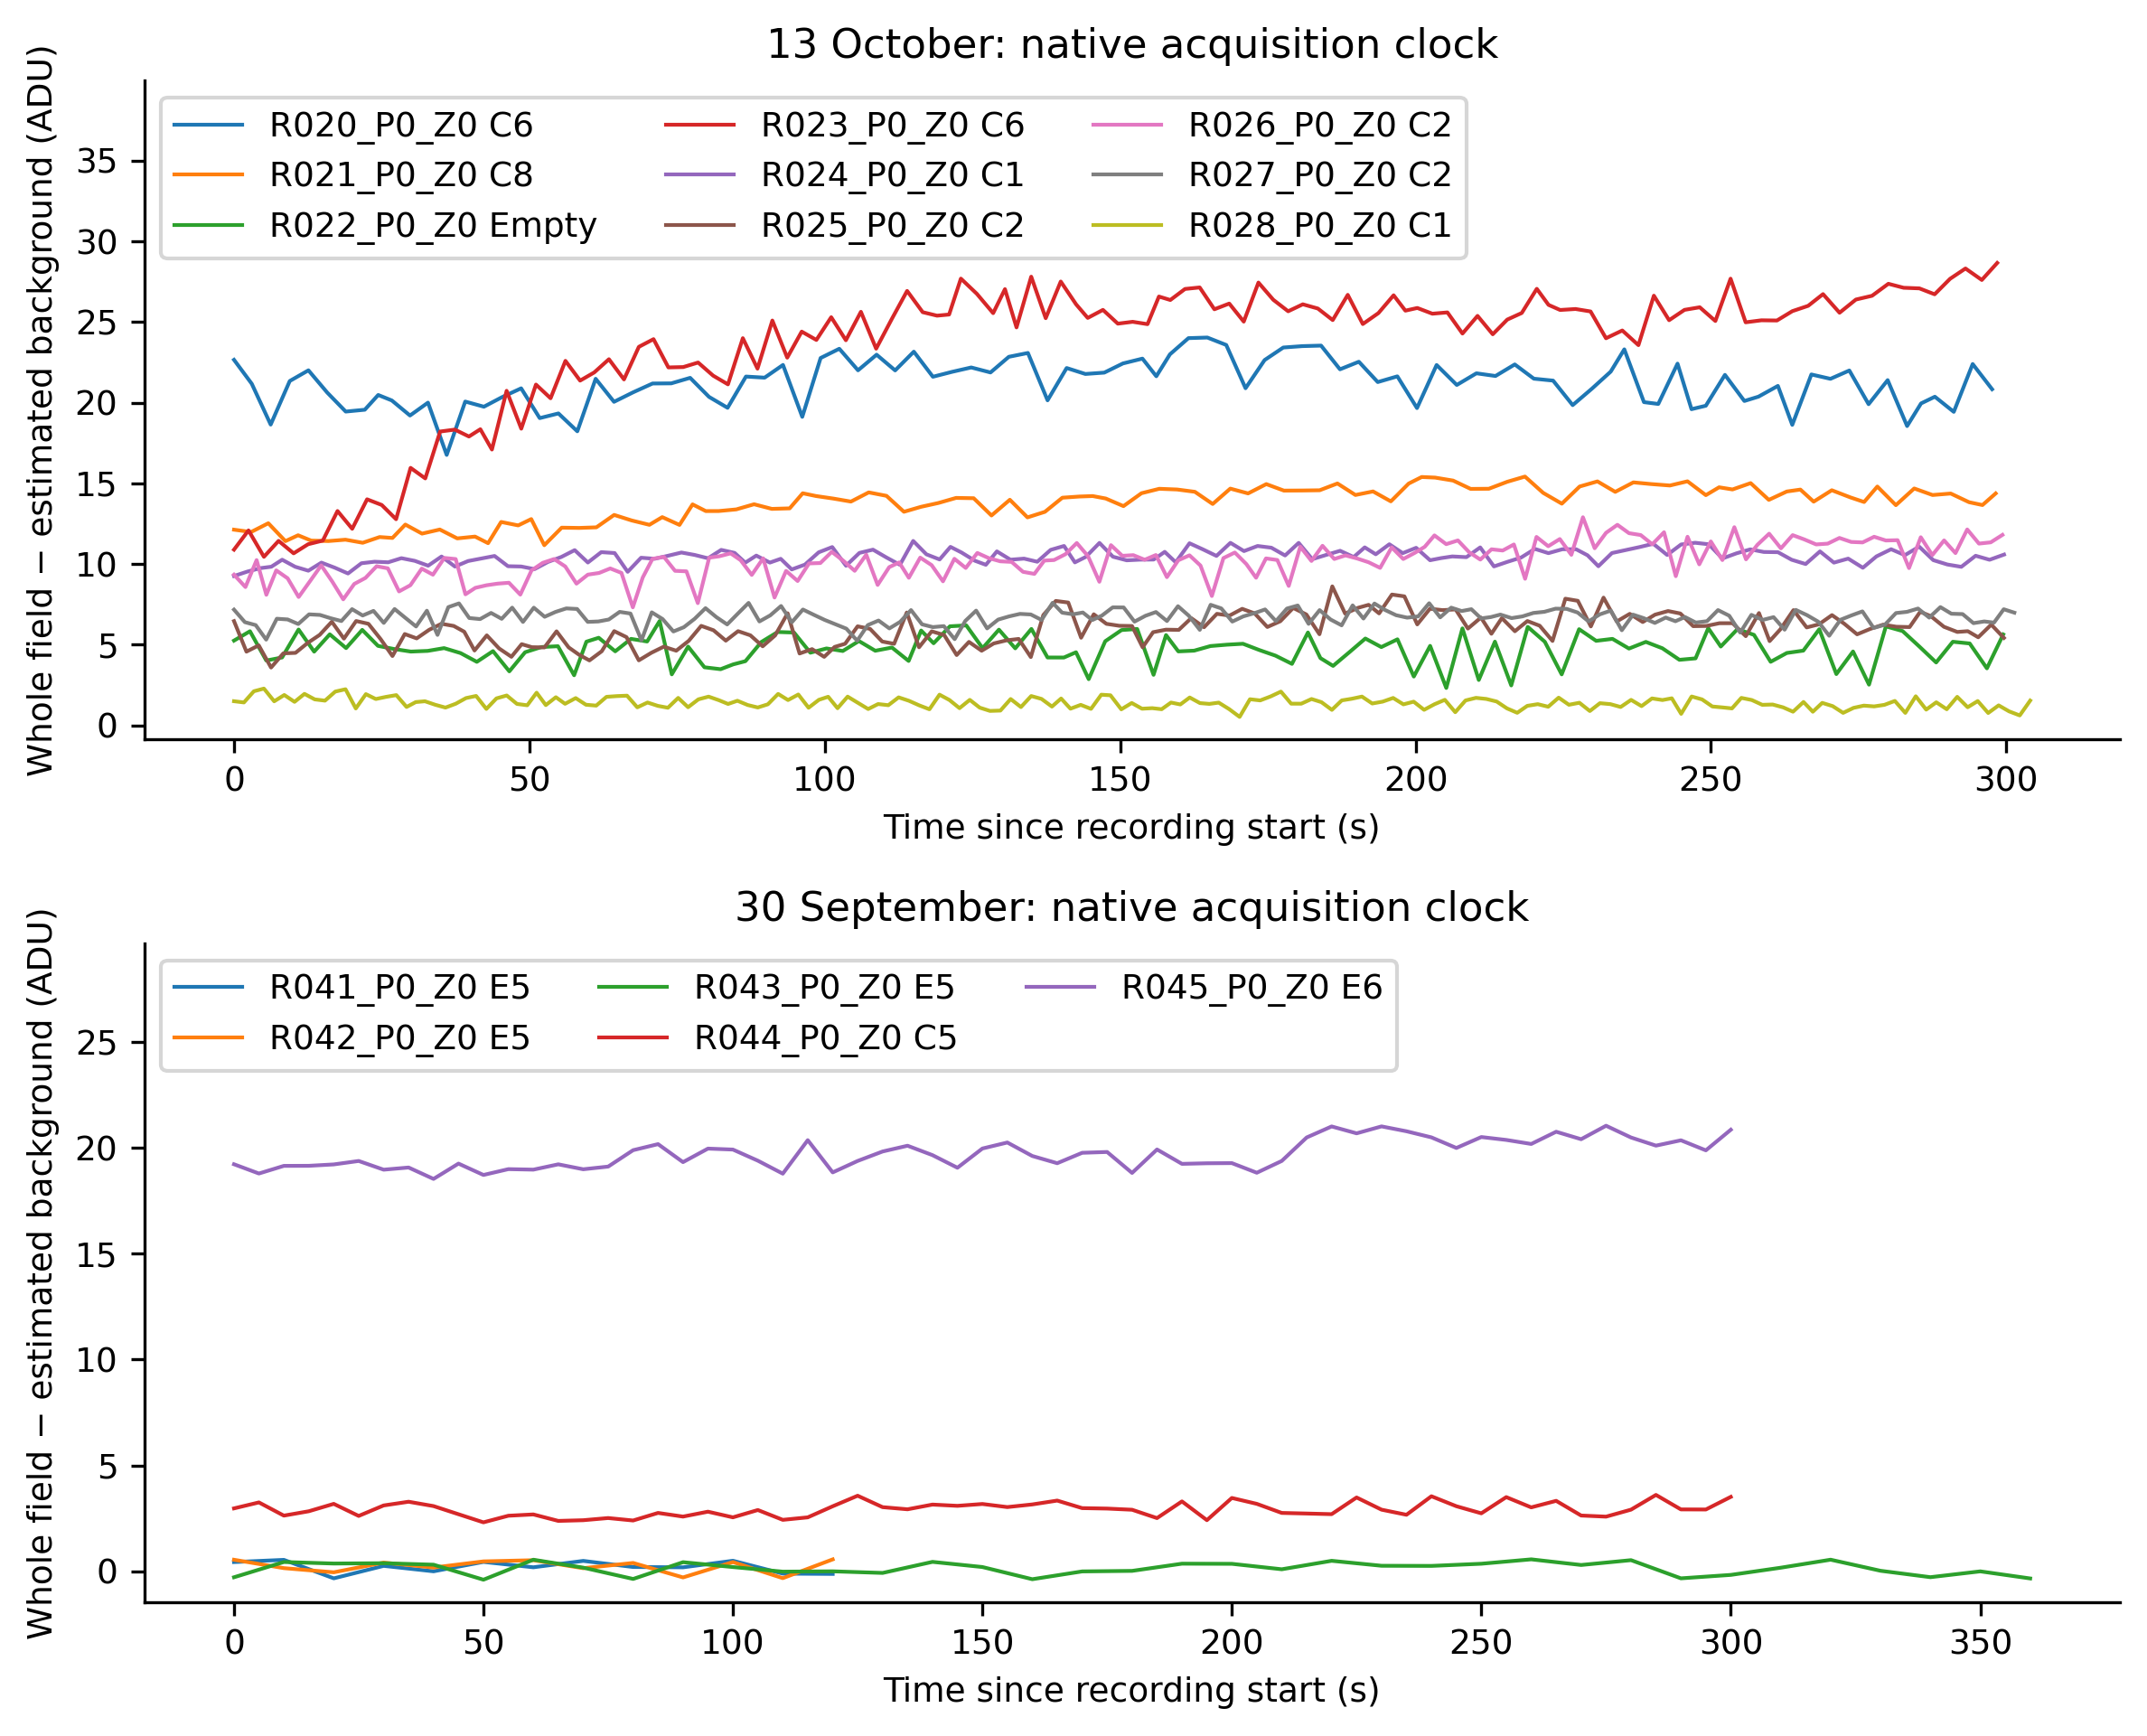

From **F-01**: All native time-series traces; references and positions belong to individual recordings. No Cd-addition frame is assumed.

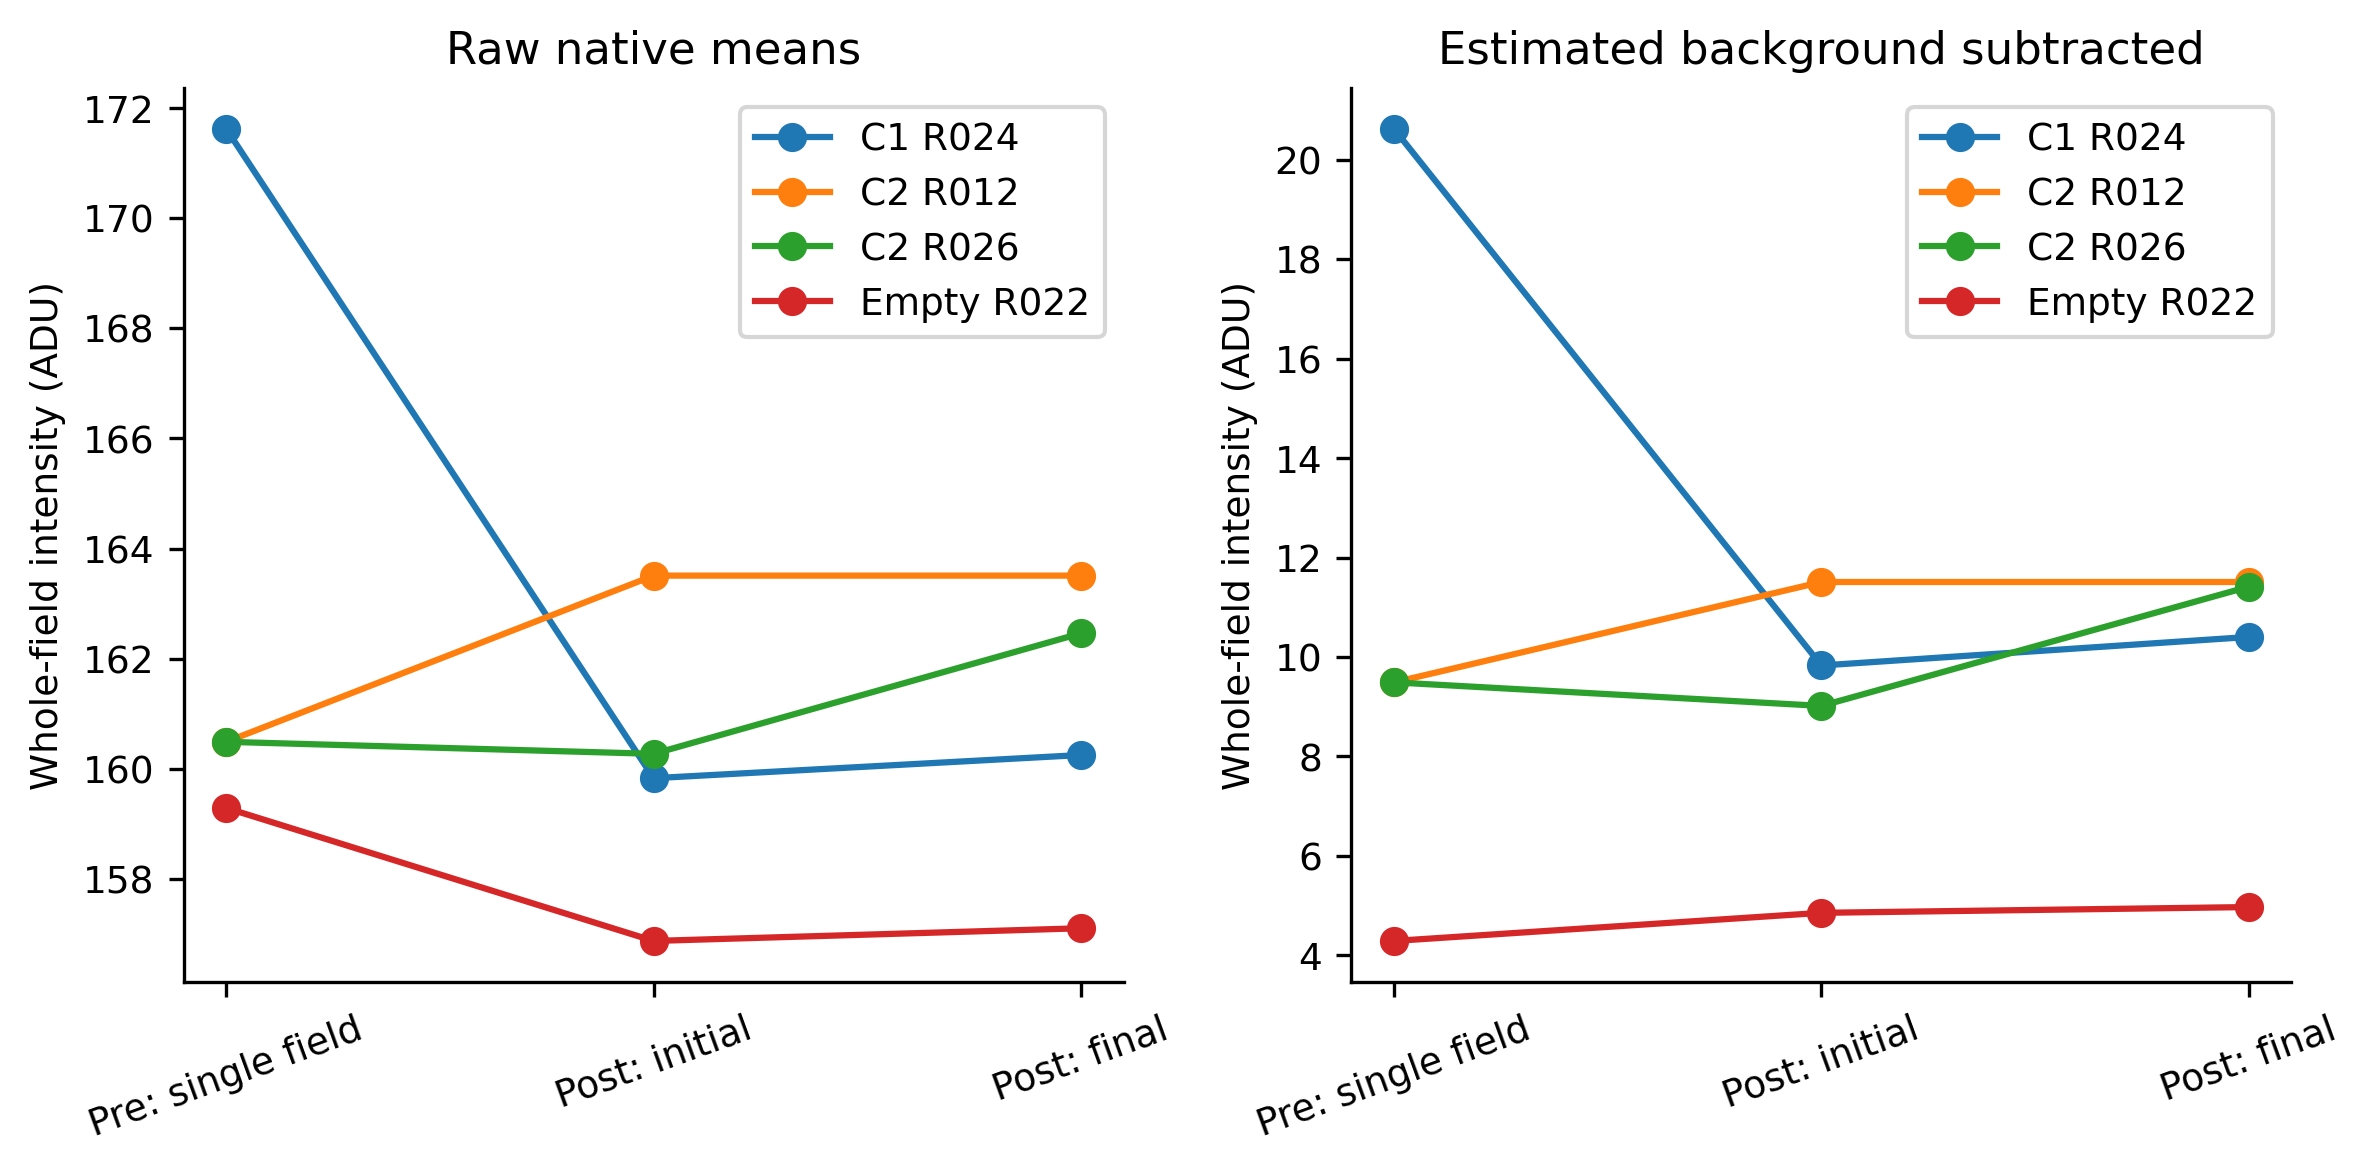

From **F-01**: Candidate same-field comparisons pass stage-distance and registered BF-correlation checks. Post values use initial/final 10% medians; the C2 calcium-conflict static file has a single post frame. C1/Empty comparisons change both calcium and cadmium labels; C2 R026 keeps nominal calcium at 1 mM. Field matching does not establish same-cell identity, equal exposure or addition time.

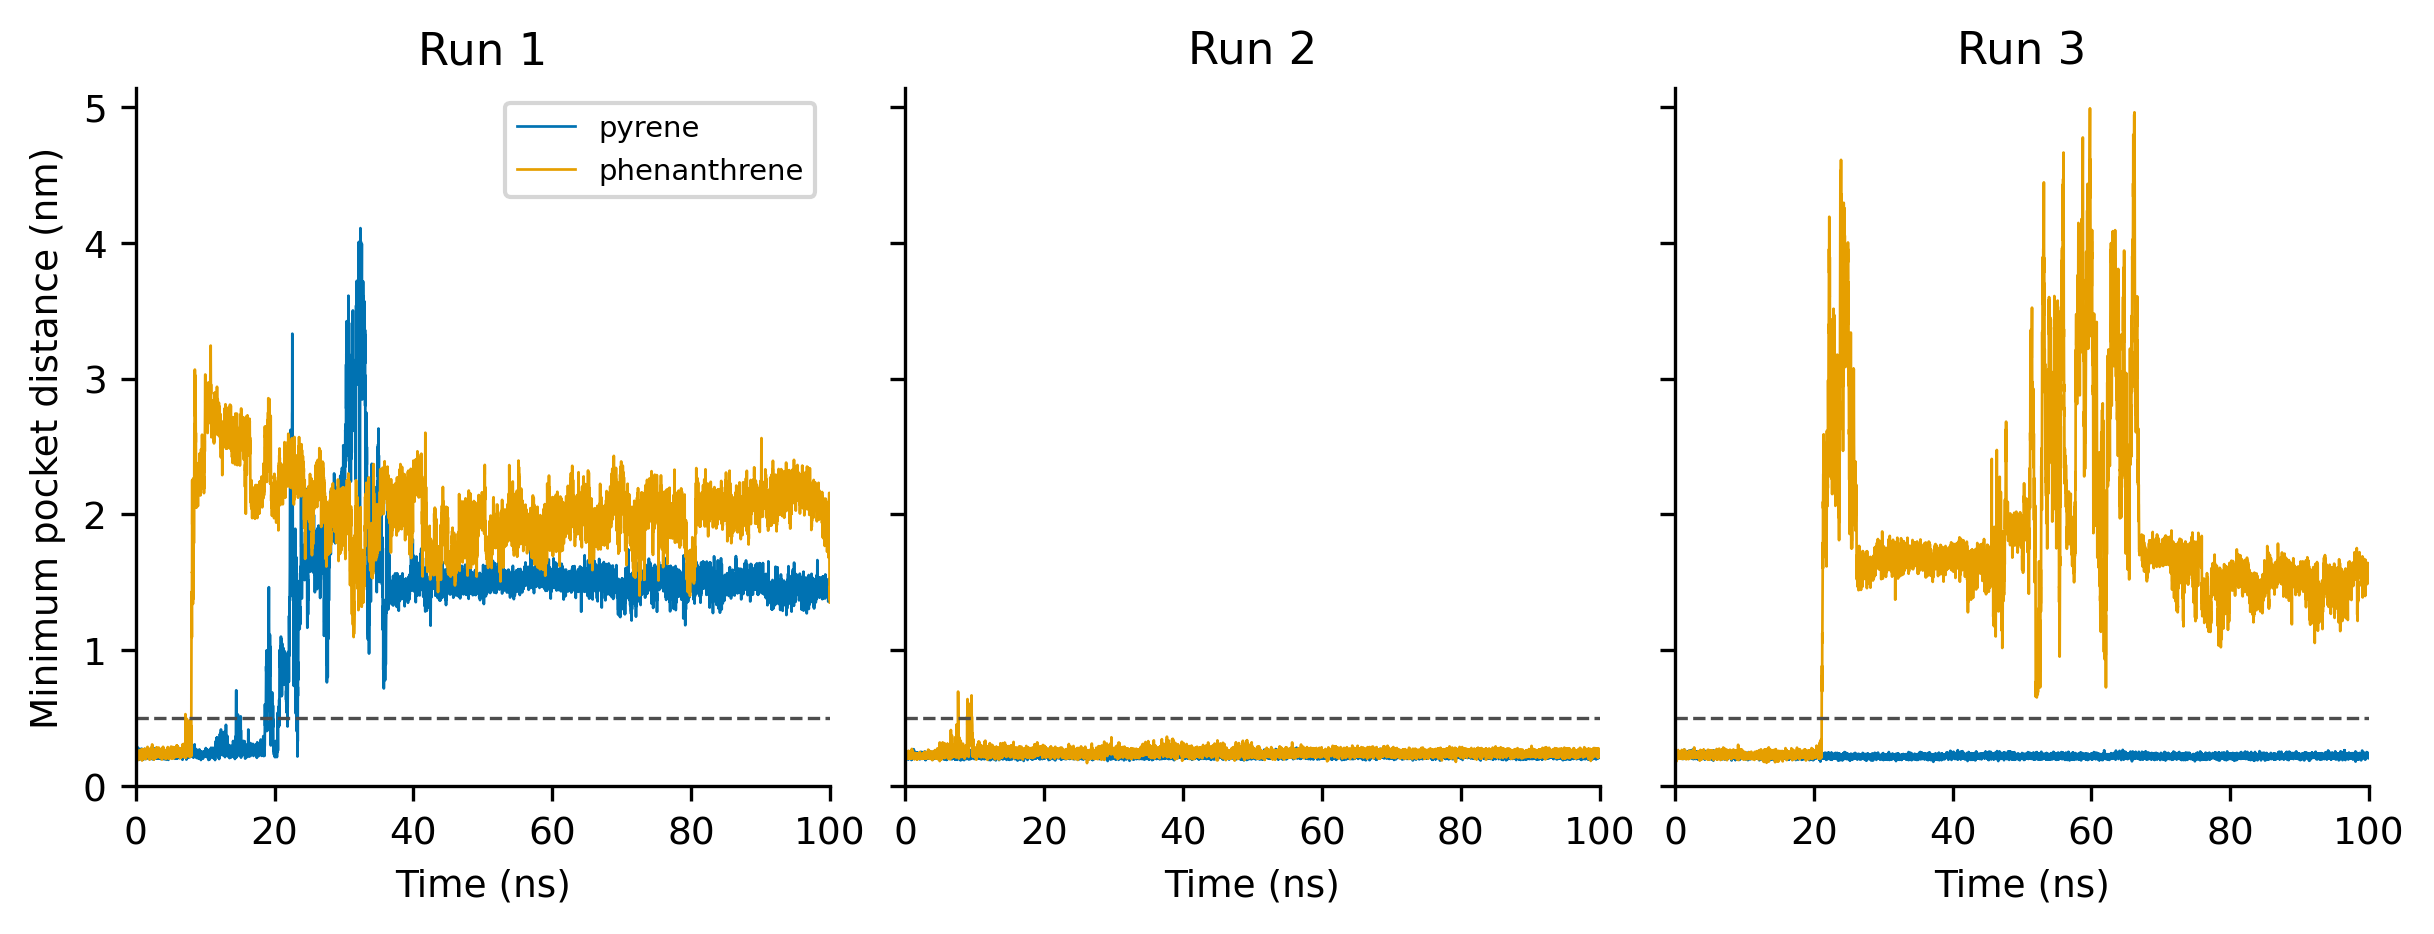

From **P-01**: All six stored finite traces; dashed line is the strict 0.5 nm criterion. Run 1 initialization differs from runs 2–3.

In [3]:
# Results: direct source statements, attributed figures and the input/scope table.
display(Markdown('## Results'))
display(report_table)
display(Markdown(draft.split('## Figures')[0]))
for item in figures:
    display(Image(filename=str(OUT / (item['output_stem'] + '.png'))))
    display(Markdown('From **' + item['task'] + '**: ' + item['caption']))

In [4]:
display(Markdown('## Conclusion and interpretation\n\n' + conclusion))

## Conclusion and interpretation

The draft integrates 7 source analyses and 3 unchanged figures with numerical statements, methods and source indexes. Native imaging findings and the reference-sequence analysis now appear alongside the evidence review and the separate PAH computations.